# Can surface history improve ATP match predictions beyond ranking?

**Starter analysis · 2015–2025 ATP men's singles**

This version documents the dataset, examines the training seasons and measures a ranking rule on the 2023 validation season. The remaining experiments are identified in Sections 3–5. To reproduce the outputs, follow the repository README to fetch the season files, then run the notebook from the repository root.

## 1. Predictive task

At the start of a tournament, predict which of two players would win a given singles match, conditional on both playing and completing it. The inputs must already be observable at that time. The prediction target is whether player A wins. When preparing the model matrix, assign the A/B positions independently of the result.

The comparison of interest is between two probability models. Both receive the players' rankings. One also receives each player's prior record on the surface of the upcoming match. A simple reference rule always picks the player with the better ranking (the smaller number).

## 2. Exploratory analysis, data collection and preprocessing

TennisMyLife distributes annual ATP match files with tournament start weeks, surfaces, player identities, rankings and results. The project covers main-draw singles at Grand Slams, Masters and tour-level events on hard, clay or grass courts. The shared loader in `scripts/baseline.py` checks identity, rankings and score eligibility and reports the first reason for each exclusion. Season counts below describe coverage. Only the training seasons contribute outcomes to the first figure. [Dataset and field descriptions](https://stats.tennismylife.org/tennis-match-database)

In [1]:
from bisect import bisect_left, bisect_right
from collections import Counter, defaultdict
from datetime import timedelta

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from scripts.baseline import load_matches, ranking_result, split_name

matches, audit = load_matches()
train = [match for match in matches if split_name(match["season"]) == "train"]
validation = [match for match in matches if split_name(match["season"]) == "validation"]
split_counts = Counter(split_name(match["season"]) for match in matches)

print("Eligible matches by season group")
for group, seasons in (("warmup", "2015"), ("train", "2016–2022"),
                       ("validation", "2023"), ("test", "2024–2025")):
    print(f"  {seasons:10} {group:12} {split_counts[group]:>7,}")

totals = Counter()
for season_counts in audit.values():
    totals.update(season_counts)
print(f"\nCleaning audit across all files: {totals['raw']:,} rows read")
for key, label in (("level", "Event level"), ("surface", "Surface"),
                   ("player_id", "Player identity"), ("ranking", "Ranking"),
                   ("score", "Score")):
    print(f"  Excluded · {label:16} {totals[key]:>7,}")
print(f"  Eligible                    {totals['eligible']:>7,}")

Eligible matches by season group
  2015       warmup         2,508
  2016–2022  train         16,188
  2023       validation     2,588
  2024–2025  test           5,088

Cleaning audit across all files: 30,716 rows read
  Excluded · Event level        3,303
  Excluded · Surface                0
  Excluded · Player identity        0
  Excluded · Ranking               70
  Excluded · Score                971
  Eligible                     26,372


### How often does the better-ranked player win?

Group training matches by the absolute difference between the opponents' rankings. The dashed line marks a 50% win rate. Labels give the win rate and the number of matches in each bin. Equal rankings have no favorite under this rule.

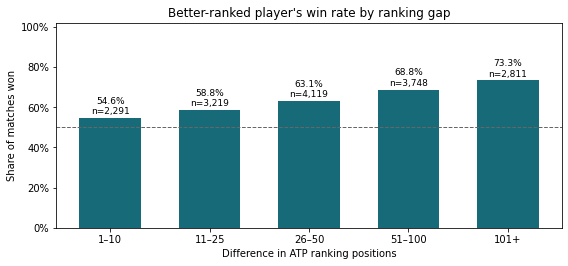

In [2]:
gap_limits = [10, 25, 50, 100]
gap_labels = ["1–10", "11–25", "26–50", "51–100", "101+"]
gap_groups = [[] for label in gap_labels]
for match in train:
    gap = abs(match["winner_rank"] - match["loser_rank"])
    if gap > 0:
        gap_groups[bisect_left(gap_limits, gap)].append(match)

gap_results = [ranking_result(group) for group in gap_groups]
win_rates = [correct / count for correct, count in gap_results]

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(gap_labels, win_rates, color="#176B78", width=0.62)
ax.axhline(0.5, color="#666666", linewidth=1, linestyle="--")
for bar, rate, (_, count) in zip(bars, win_rates, gap_results):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02,
            f"{rate:.1%}\nn={count:,}", ha="center", fontsize=9)
ax.set(title="Better-ranked player's win rate by ranking gap",
       xlabel="Difference in ATP ranking positions", ylabel="Share of matches won",
       ylim=(0, 1.02))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

For a gap of 1–10 places, the favorite won 54.6% of training matches. For a gap of 101 or more places, the rate was 73.3%. Ranking therefore supplies a meaningful starting point, especially when the players are far apart.

### How much same-surface history is available before a tournament?

Count eligible prior matches for each player appearing in each training match. History can draw on the 2015 warm-up season and earlier training matches. For a tournament starting on date $d$, count starts from $d-364$ through $d-21$ days, inclusive. The three-week buffer handles the fact that every round in an event shares its start week.

Each player appearance contributes once, so a player competing in several matches contributes several observations. Percentages are calculated within each surface.

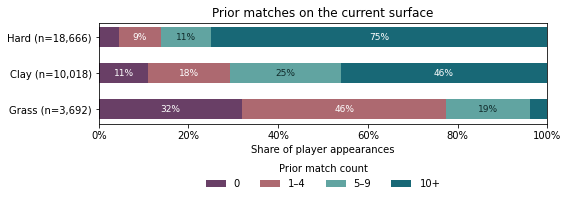

Hard: 2,580 of 18,666 appearances had fewer than five prior matches (13.8%).
Clay: 2,942 of 10,018 appearances had fewer than five prior matches (29.4%).
Grass: 2,861 of 3,692 appearances had fewer than five prior matches (77.5%).


In [3]:
prior_dates = defaultdict(list)
for match in matches:
    if split_name(match["season"]) in {"warmup", "train"}:
        for player in (match["winner_id"], match["loser_id"]):
            prior_dates[player, match["surface"]].append(match["tourney_date"])
for dates in prior_dates.values():
    dates.sort()

surfaces = ["Hard", "Clay", "Grass"]
coverage_labels = ["0", "1–4", "5–9", "10+"]
coverage = {surface: Counter() for surface in surfaces}
for match in train:
    surface = match["surface"]
    start = match["tourney_date"]
    for player in (match["winner_id"], match["loser_id"]):
        dates = prior_dates[player, surface]
        first = bisect_left(dates, start - timedelta(weeks=52))
        last = bisect_right(dates, start - timedelta(days=21))
        prior_matches = last - first
        bucket = bisect_left([0, 4, 9], prior_matches)
        coverage[surface][bucket] += 1

counts = [sum(coverage[surface].values()) for surface in surfaces]
assert sum(counts) == 2 * len(train)
colors = ["#693F66", "#AD6970", "#61A4A1", "#186876"]
fig, ax = plt.subplots(figsize=(8, 3.2))
left = [0.0] * len(surfaces)
for bucket, (label, color) in enumerate(zip(coverage_labels, colors)):
    shares = [coverage[surface][bucket] / n for surface, n in zip(surfaces, counts)]
    ax.barh(surfaces, shares, left=left, height=0.55, label=label, color=color)
    for i, share in enumerate(shares):
        if share >= 0.08:
            ax.text(left[i] + share / 2, i, f"{share:.0%}", ha="center",
                    va="center", color="white" if bucket != 2 else "#102B2B", fontsize=9)
    left = [a + b for a, b in zip(left, shares)]
ax.set_yticks(range(len(surfaces)))
ax.set_yticklabels([f"{s} (n={n:,})" for s, n in zip(surfaces, counts)])
ax.invert_yaxis()
ax.set(title="Prior matches on the current surface", xlabel="Share of player appearances",
       xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Prior match count", ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.31), frameon=False)
fig.tight_layout()
plt.show()

for surface, n in zip(surfaces, counts):
    sparse = coverage[surface][0] + coverage[surface][1]
    print(f"{surface}: {sparse:,} of {n:,} appearances had fewer than five prior matches ({sparse/n:.1%}).")

Grass has the sparsest history: 77.5% of training appearances have fewer than five eligible prior grass matches under this window. The corresponding shares are 29.4% on clay and 13.8% on hard courts. This motivates shrinking small-sample win rates toward 0.5 before comparing the models.

## 3. Modeling

**Implemented reference.** The ranking rule predicts a winner for each match with distinct rankings. No fitting is required.

**Next experiment.** Assign each match an A/B orientation that does not depend on its outcome. Fit a regularized logistic regression on the difference in log rankings. Fit a second regression on that difference plus the difference in smoothed same-surface win rates, using the window from Section 2. For a player's historical $w$ wins from $n$ matches, use $(w+1)/(n+2)$. A player with zero eligible matches starts at 0.5. Past opponents and schedule difficulty may affect these rates.

Train on 2016–2022 and choose settings using 2023. Freeze the models and evaluation choices before computing test metrics. In the completed notebook, walk through the A/B assignment, prior wins and sample count for one match.

## 4. Evaluation

First measure the always-pick-the-better-ranking rule on validation matches. Ties in ranking have no rule-based pick and are excluded from the denominator. Apply the same eligibility rule for model comparisons.

In [4]:
correct, scored = ranking_result(validation)
print("2023 validation · pick the better-ranked player")
print(f"Correct picks: {correct:,} / {scored:,} ({correct / scored:.2%})")
print(f"Equal-ranking matches without a pick: {len(validation) - scored:,}")

2023 validation · pick the better-ranked player
Correct picks: 1,640 / 2,588 (63.37%)
Equal-ranking matches without a pick: 0


**Pending final evaluation.** Score the frozen models on exactly the same eligible matches from 2024 and 2025. Show sample counts, accuracy and accuracy changes in percentage points; also report log loss for the two probability models. Compare their differences in each test season and overall. Use the full test set to support the conclusion and one match to illustrate it.

## 5. Discussion of related work

Kovalchik compares ranking-based and other methods for predicting professional tennis matches. This motivates measuring how much a ranking rule already explains. [Kovalchik (2016)](https://doi.org/10.1515/jqas-2015-0059)

Vaughan Williams and coauthors study Elo ratings and tennis forecasts. Their treatment of court surfaces gives a comparison for our simpler historical win-rate feature, which does not adjust wins for opponent strength. [Vaughan Williams et al. (2021)](https://doi.org/10.1515/jqas-2019-0110)

**Pending after evaluation.** Compare the direction and scale of our observed effect with the papers' findings. Identify differences in seasons, player populations and predictors that affect the interpretation.